In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm

In [4]:
campaigns = pd.read_csv('../data/northbound_campaigns.csv')
campaigns['impressions_k'] = campaigns['impressions'] / 1000
search = campaigns.loc[campaigns['channel'] == 'Search']

In [5]:
search_model = sm.ols('conversions ~ impressions_k', data=search).fit()

In [6]:
search_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            conversions   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     444.9
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.38e-46
Time:                        15:07:44   Log-Likelihood:                -893.25
No. Observations:                 151   AIC:                             1790.
Df Residuals:                     149   BIC:                             1797.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         5.0398     16.835      0.299      0.765     -28.225      38.305
impressions_k     1.5406      0.073     21.092      0.000       1.396       1.685
==============================================================================
Omnibus:                        3.102   Durbin-Watson:                   1.357
Prob(Omnibus):                  0.212   Jarque-Bera (JB):                3.114
Skew:                           0.342   Prob(JB):                        0.211
Kurtosis:                       2.837   Cond. No.                         528.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [7]:
print(search_model.summary())

                            OLS Regression Results                            
Dep. Variable:            conversions   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     444.9
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.38e-46
Time:                        15:08:09   Log-Likelihood:                -893.25
No. Observations:                 151   AIC:                             1790.
Df Residuals:                     149   BIC:                             1797.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         5.0398     16.835      0.299

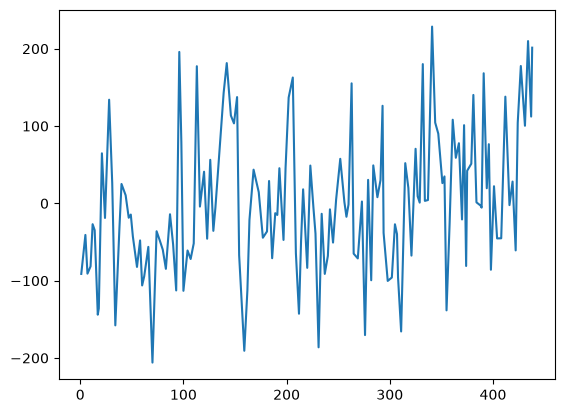

In [8]:
plt.plot(search_model.resid)

In [9]:
search['resid'] = search_model.resid
search = search.sort_values('impressions_k', ascending=True)
search.tail()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue,impressions_k,resid
311,NB0312,2025-02-17,Search,0,10816.91,455427,15912,541,49745.78,455.427,-165.690112
434,NB0435,2025-12-15,Search,0,11475.94,470610,17494,940,90259.37,470.610,209.918310
276,NB0277,2024-11-04,Search,0,10134.43,473394,18797,564,52508.41,473.394,-170.370839
381,NB0382,2025-08-11,Search,1,10062.30,506765,18995,926,77381.70,506.765,140.216374
321,NB0322,2025-03-10,Search,1,10218.90,536484,18291,764,62091.48,536.484,-67.569986


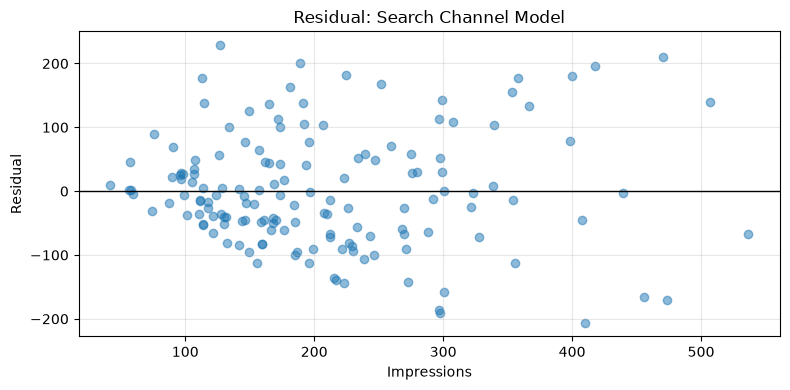

In [14]:
plt.figure(figsize=(8, 4))
plt.scatter(search['impressions_k'], search['resid'], color='tab:blue', alpha=.5)
plt.axhline(0, color='black', linewidth=1)
plt.title('Residual: Search Channel Model')
plt.ylabel('Residual')
plt.xlabel('Impressions')
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

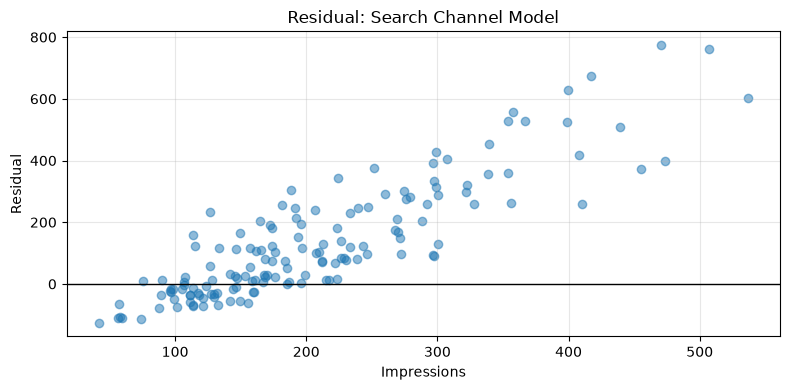

In [20]:
pooled_model = sm.ols('conversions ~ impressions_k', data=campaigns).fit()
search['resid'] = pooled_model.resid
search = search.sort_values('impressions_k', ascending=True)
plt.figure(figsize=(8, 4))
plt.scatter(search['impressions_k'], search['resid'], color='tab:blue', alpha=.5)
plt.axhline(0, color='black', linewidth=1)
plt.title('Residual: Search Channel Model')
plt.ylabel('Residual')
plt.xlabel('Impressions')
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()